# Creep vs. elastic designs (Sec. 4.1)

Generates `figures/elastic_vs_creep.pdf` and its panels, `figures/panels/1A.pdf` to `1E.pdf`.

Reads `results/1_creep_elastic/` and the V\* = 0.5 design from `results/2_pareto_vf/`.

In [1]:
import pickle

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import PolyCollection
from pypdf import PageObject, PdfReader, PdfWriter, Transformation

from plot_utils import FIGURES, PANELS, RESULTS, draw_cantilever_bcs, load_design, plot_field, specimen_cmap

VF = 0.5
RUN_DIR = RESULTS / "1_creep_elastic"
ELASTIC_VTU = RUN_DIR / "data_elastic_50" / "vtk" / "sol_250.vtu"
CREEP_VTU = RESULTS / "2_pareto_vf" / "data_creep_50" / "vtk" / "sol_250.vtu"
PANELS.mkdir(parents=True, exist_ok=True)

## 1A: displacement over the service life

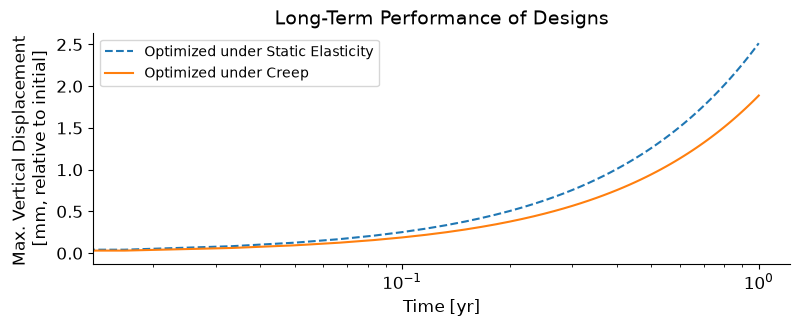

In [2]:
with open(RUN_DIR / "data_evaluation" / "creep_solution_for_elastic_design.pkl", "rb") as f:
    elastic_sol = pickle.load(f)
with open(RUN_DIR / "data_evaluation" / "creep_solution_for_creep_design.pkl", "rb") as f:
    creep_sol = pickle.load(f)

max_disp_elastic = np.max(np.abs(elastic_sol[:, :, 1]), axis=1) * 1e3
max_disp_creep = np.max(np.abs(creep_sol[:, :, 1]), axis=1) * 1e3
max_disp_elastic = max_disp_elastic - max_disp_elastic[0]
max_disp_creep = max_disp_creep - max_disp_creep[0]

time = np.linspace(0, 1, num=elastic_sol.shape[0])  # years

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time, max_disp_elastic, "--", label="Optimized under Static Elasticity")
ax.plot(time, max_disp_creep, "-", label="Optimized under Creep")
ax.set_xlabel("Time [yr]", fontsize=12)
ax.set_ylabel("Max. Vertical Displacement \n[mm, relative to initial]", fontsize=12)
ax.set_title("Long-Term Performance of Designs", fontsize=14)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xscale("log")
ax.legend()
ax.tick_params(labelsize=12)
fig.savefig(PANELS / "1A.pdf", bbox_inches="tight", pad_inches=0.1)
plt.show()

## 1B: design domain and boundary conditions

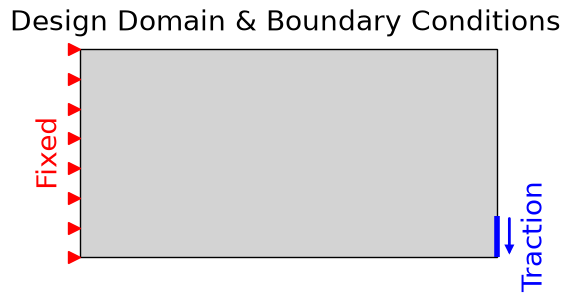

In [3]:
design = load_design(ELASTIC_VTU, VF)
(xmin, ymin), (xmax, ymax) = design.points.min(axis=0), design.points.max(axis=0)

fig, ax = plt.subplots(figsize=(6, 3))
ax.set_aspect("equal")
ax.set_axis_off()
ax.add_collection(PolyCollection(design.points[design.cells], facecolors="lightgray", linewidths=0.3))
ax.autoscale_view()
draw_cantilever_bcs(ax, design.points, scale=1.0)
ax.text(xmin - 15.0, 0.5 * (ymin + ymax), "Fixed", color="red", ha="center", va="center",
        rotation=90, fontsize=20, clip_on=False, zorder=6)
ax.text(xmax + 18.0, ymin + 0.1 * (ymax - ymin), "Traction", color="blue", ha="center", va="center",
        rotation=90, fontsize=20, clip_on=False, zorder=6)
ax.set_title("Design Domain & Boundary Conditions", fontsize=20)
fig.savefig(PANELS / "1B.pdf")
plt.show()

## 1C and 1D: optimized designs

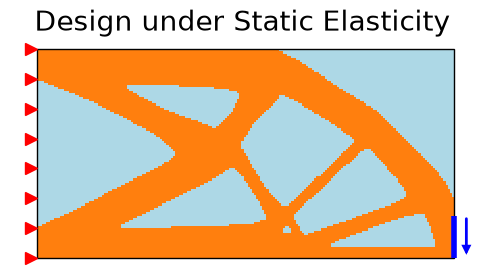

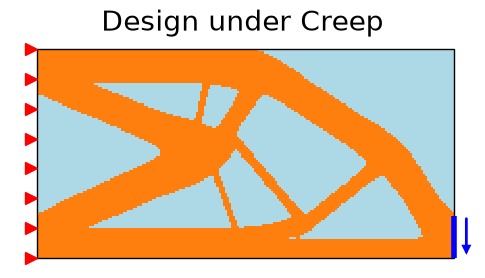

In [4]:
for vtu_path, label, panel in ((ELASTIC_VTU, "Static Elasticity", "1C"), (CREEP_VTU, "Creep", "1D")):
    design = load_design(vtu_path, VF)
    fig, ax = plt.subplots(figsize=(6, 3))
    plot_field(ax, design, design.binary, cmap=specimen_cmap, vmin=0.0, vmax=1.0, border=False)
    draw_cantilever_bcs(ax, design.points, scale=1.0)
    ax.set_title(f"Design under {label}", fontsize=20)
    fig.savefig(PANELS / f"{panel}.pdf")
    plt.show()

## 1E: colorbar

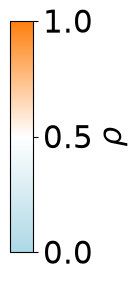

In [5]:
fig, ax = plt.subplots(figsize=(0.3, 3.0))
sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=0.0, vmax=1.0), cmap=specimen_cmap)
cbar = fig.colorbar(sm, cax=ax, label=r"$\rho$")
cbar.set_ticks([0.0, 0.5, 1.0])
cbar.ax.tick_params(labelsize=22)
cbar.ax.yaxis.label.set_size(22)
fig.savefig(PANELS / "1E.pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()

## Assemble the figure

1A spans the top row, and 1B to 1E form the bottom row.

In [6]:
ROW_SCALE = 0.5  # Scale of the bottom row

top_page = PdfReader(PANELS / "1A.pdf").pages[0]
row_pages = [PdfReader(PANELS / f"{panel}.pdf").pages[0] for panel in ("1B", "1C", "1D", "1E")]

top_w, top_h = float(top_page.mediabox.width), float(top_page.mediabox.height)
sizes = [(float(p.mediabox.width) * ROW_SCALE, float(p.mediabox.height) * ROW_SCALE) for p in row_pages]
row_w = sum(w for w, _ in sizes)
row_h = max(h for _, h in sizes)
canvas_w = max(top_w, row_w)

canvas = PageObject.create_blank_page(width=canvas_w, height=top_h + row_h)
x = (canvas_w - row_w) / 2
for page, (w, h) in zip(row_pages, sizes):
    canvas.merge_transformed_page(page, Transformation().scale(ROW_SCALE).translate(x, (row_h - h) / 2))
    x += w
canvas.merge_transformed_page(top_page, Transformation().translate((canvas_w - top_w) / 2, row_h))

writer = PdfWriter()
writer.add_page(canvas)
with open(FIGURES / "elastic_vs_creep.pdf", "wb") as f:
    writer.write(f)